# Exploratory data analysis
NS Intercity and Sprinter services, Aug 2024 - Aug 2026 (Rijden de Treinen archive).

**Summary**
- Data: NS Intercity + Sprinter, Aug 2024 - Aug 2026, ~24.7M arrivals that weren't cancelled.
- Cleaning: drop cancelled arrivals (they have delay 0), drop runs with a delay over 600 min (24h date errors), keep only NL stations.
- Label: late = 5+ min, about 5% of arrivals. Accuracy is useless, so I'll use average precision.
- Time: late rate is seasonal (autumn ~7-8%, summer ~4%), so the test period (Mar-Aug 2026) will look calmer than train. Rolling history instead of a fixed rate.
- Useful features: hour (delays build up during the day), weekday (weekend calmer), train type (IC ~1.5x Sprinter), station (2-10%).
- Hardest part: 71% of trains aren't running yet one hour before, and they account for ~61% of the late arrivals.

In [1]:
import sys
sys.path.append("..")

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from src.config import RAW, DELAY_THRESHOLD_MIN

pd.set_option("display.max_columns", None)
con = duckdb.connect()
con.sql("set TimeZone = 'Europe/Amsterdam'")

In [2]:
month = RAW / "services-2025-03.csv.gz"
con.sql(f"select * from read_csv('{month}') limit 10").df()

,Service:RDT-ID,Service:Date,Service:Type,Service:Company,Service:Train number,Service:Completely cancelled,Service:Partly cancelled,Service:Maximum delay,Stop:RDT-ID,Stop:Station code,Stop:Station name,Stop:Arrival time,Stop:Arrival delay,Stop:Arrival cancelled,Stop:Departure time,Stop:Departure delay,Stop:Departure cancelled,Stop:Platform change,Stop:Planned platform,Stop:Actual platform
0,15465220,2025-03-01,Intercity,NS,21461,False,False,3,139779709,HLM,Haarlem,NaT,<NA>,<NA>,2025-03-01 02:01:00+01:00,3,False,False,1,1
1,15465220,2025-03-01,Intercity,NS,21461,False,False,0,139779710,ASD,Amsterdam Centraal,2025-03-01 02:14:00+01:00,3,False,NaT,<NA>,<NA>,False,7a,7a
2,15465221,2025-03-01,Nightjet,NS Int,420,False,False,44,139779711,NURNB,Nürnberg Hbf,NaT,<NA>,<NA>,2025-03-01 02:01:00+01:00,0,False,False,NaN,NaN
3,15465221,2025-03-01,Nightjet,NS Int,420,False,False,0,139779712,WURZB,Würzburg Hbf,2025-03-01 02:30:00+01:00,0,False,2025-03-01 02:32:00+01:00,0,False,False,NaN,NaN
4,15465221,2025-03-01,Nightjet,NS Int,420,False,False,0,139779713,FFFM,Frankfurt (M) Hbf,2025-03-01 04:55:00+01:00,0,False,2025-03-01 05:00:00+01:00,0,False,False,NaN,NaN
5,15465221,2025-03-01,Nightjet,NS Int,420,False,False,0,139779714,HAMM,Hamm (Westf.),2025-03-01 06:28:00+01:00,0,False,2025-03-01 06:30:00+01:00,0,False,False,NaN,NaN
6,15465221,2025-03-01,Nightjet,NS Int,420,False,False,0,139779715,MUNST,Münster (Westf) Hbf,2025-03-01 06:51:00+01:00,0,False,2025-03-01 06:54:00+01:00,0,False,False,NaN,NaN
7,15465221,2025-03-01,Nightjet,NS Int,420,False,False,0,139779716,RHEINE,Rheine,2025-03-01 07:14:00+01:00,44,False,2025-03-01 07:19:00+01:00,41,False,False,NaN,NaN
8,15465221,2025-03-01,Nightjet,NS Int,420,False,False,0,139779717,BH,Bad Bentheim,2025-03-01 07:40:00+01:00,33,False,2025-03-01 07:41:00+01:00,35,False,False,NaN,NaN
9,15465221,2025-03-01,Nightjet,NS Int,420,False,False,0,139779718,DV,Deventer,2025-03-01 08:34:00+01:00,33,False,2025-03-01 08:37:00+01:00,32,False,False,4,4


In [3]:
con.sql(f"""
    with s as (select * from read_csv('{month}'))
    select * from s
    where "Service:RDT-ID" = (
        select "Service:RDT-ID" from s
        where "Service:Company" = 'NS' and "Service:Type" = 'Intercity' and "Service:Date" = '2025-03-12'
        group by 1 having count(*) >= 8
        order by 1 limit 1)
    order by coalesce("Stop:Arrival time", "Stop:Departure time")
""").df()

,Service:RDT-ID,Service:Date,Service:Type,Service:Company,Service:Train number,Service:Completely cancelled,Service:Partly cancelled,Service:Maximum delay,Stop:RDT-ID,Stop:Station code,Stop:Station name,Stop:Arrival time,Stop:Arrival delay,Stop:Arrival cancelled,Stop:Departure time,Stop:Departure delay,Stop:Departure cancelled,Stop:Platform change,Stop:Planned platform,Stop:Actual platform
0,15536554,2025-03-12,Intercity,NS,1714,False,False,1,140450231,ES,Enschede,NaT,<NA>,<NA>,2025-03-12 04:46:00+01:00,0,False,True,2,3
1,15536554,2025-03-12,Intercity,NS,1714,False,False,0,140450232,HGL,Hengelo,2025-03-12 04:53:00+01:00,0,False,2025-03-12 04:54:00+01:00,1,False,False,3a,3a
2,15536554,2025-03-12,Intercity,NS,1714,False,False,0,140450233,AML,Almelo,2025-03-12 05:05:00+01:00,1,False,2025-03-12 05:06:00+01:00,1,False,False,4,4
3,15536554,2025-03-12,Intercity,NS,1714,False,False,0,140450234,DV,Deventer,2025-03-12 05:30:00+01:00,0,False,2025-03-12 05:33:00+01:00,0,False,False,4,4
4,15536554,2025-03-12,Intercity,NS,1714,False,False,0,140450235,APD,Apeldoorn,2025-03-12 05:43:00+01:00,0,False,2025-03-12 05:44:00+01:00,0,False,False,1,1
5,15536554,2025-03-12,Intercity,NS,1714,False,False,0,140450236,AMF,Amersfoort Centraal,2025-03-12 06:08:00+01:00,0,False,2025-03-12 06:10:00+01:00,0,False,False,6,6
6,15536554,2025-03-12,Intercity,NS,1714,False,False,0,140450237,UT,Utrecht Centraal,2025-03-12 06:23:00+01:00,1,False,2025-03-12 06:28:00+01:00,0,False,False,8,8
7,15536554,2025-03-12,Intercity,NS,1714,False,False,0,140450238,GD,Gouda,2025-03-12 06:46:00+01:00,0,False,2025-03-12 06:47:00+01:00,0,False,False,8,8
8,15536554,2025-03-12,Intercity,NS,1714,False,False,0,140450239,GVC,Den Haag Centraal,2025-03-12 07:06:00+01:00,0,False,NaT,<NA>,<NA>,False,5,5


### What a row is
Each row is one stop of one train run. The RDT-ID identifies the run (one train on one day), the train number is the same every day.
First stop has no arrival, last stop has no departure.
Times are the planned times (with UTC offset). Delay is in whole minutes, so actual = planned + delay.
Max delay is only on the first row of a run and is only known after the trip anyway, so I leave it out.

In [4]:
con.sql(f"""
    create table stops as
    select
        "Service:RDT-ID" as service_id,
        "Service:Date" as service_date,
        "Service:Type" as train_type,
        "Service:Train number" as train_number,
        "Service:Completely cancelled" as service_cancelled,
        "Stop:RDT-ID" as stop_id,
        "Stop:Station code" as station,
        "Stop:Arrival time" as arr_time,
        "Stop:Arrival delay" as arr_delay,
        "Stop:Arrival cancelled" as arr_cancelled,
        "Stop:Departure time" as dep_time,
        "Stop:Departure delay" as dep_delay,
        "Stop:Departure cancelled" as dep_cancelled
    from read_csv('{RAW}/services-*.csv.gz', union_by_name = true)
    where "Service:Company" = 'NS' and "Service:Type" in ('Intercity', 'Sprinter')
""")

con.sql("""
    select count(*) as stop_rows, count(distinct service_id) as services, count(arr_time) as arrivals,
           min(service_date) as first_day, max(service_date) as last_day
    from stops
""").show()

┌───────────┬──────────┬──────────┬────────────┬────────────┐
│ stop_rows │ services │ arrivals │ first_day  │  last_day  │
│   int64   │  int64   │  int64   │    date    │    date    │
├───────────┼──────────┼──────────┼────────────┼────────────┤
│  29149592 │  2735775 │ 26408723 │ 2024-08-01 │ 2026-08-31 │
└───────────┴──────────┴──────────┴────────────┴────────────┘



After filtering to NS Intercity and Sprinter: 29.1M stops, 2.74M runs, 26.4M arrivals.
Around 5k arrivals are missing even though they're not the first stop. Probably split trains, too few to care about.

In [5]:
con.sql("""
    select
        count(*) as arrivals,
        count(*) filter (where arr_cancelled) as cancelled,
        count(*) filter (where service_cancelled) as in_cancelled_service,
        count(*) filter (where arr_delay is null) as no_delay,
        count(*) filter (where arr_delay is null and not arr_cancelled) as no_delay_not_cancelled,
        min(arr_delay) as min_delay,
        max(arr_delay) as max_delay
    from stops
    where arr_time is not null
""").show()

┌──────────┬───────────┬──────────────────────┬──────────┬────────────────────────┬───────────┬───────────┐
│ arrivals │ cancelled │ in_cancelled_service │ no_delay │ no_delay_not_cancelled │ min_delay │ max_delay │
│  int64   │   int64   │        int64         │  int64   │         int64          │   int64   │   int64   │
├──────────┼───────────┼──────────────────────┼──────────┼────────────────────────┼───────────┼───────────┤
│ 26408723 │   1714194 │               464386 │        0 │                      0 │         0 │      1446 │
└──────────┴───────────┴──────────────────────┴──────────┴────────────────────────┴───────────┴───────────┘



### Missing / cancelled
1.7M arrivals are cancelled. 464k of those are runs that were cancelled completely.
Delay is never missing. It's also never negative, so early trains just show 0.
Max delay is 1446 min, which looks wrong. Checked below.

In [6]:
con.sql("""
    select arr_delay, count(*) as n
    from stops
    where arr_cancelled
    group by 1 order by n desc limit 5
""").show()

con.sql("""
    select
        count(*) filter (where arr_delay >= 60) as over_1h,
        count(*) filter (where arr_delay >= 180) as over_3h,
        count(*) filter (where arr_delay >= 600) as over_10h
    from stops
    where arr_time is not null and not arr_cancelled
""").show()

con.sql("""
    select service_date, train_type, train_number, station, arr_time, arr_delay
    from stops
    where not arr_cancelled
    order by arr_delay desc limit 10
""").show()

┌───────────┬─────────┐
│ arr_delay │    n    │
│   int64   │  int64  │
├───────────┼─────────┤
│         0 │ 1714194 │
└───────────┴─────────┘

┌─────────┬─────────┬──────────┐
│ over_1h │ over_3h │ over_10h │
│  int64  │  int64  │  int64   │
├─────────┼─────────┼──────────┤
│    1315 │      43 │        6 │
└─────────┴─────────┴──────────┘

┌──────────────┬────────────┬──────────────┬─────────┬──────────────────────────┬───────────┐
│ service_date │ train_type │ train_number │ station │         arr_time         │ arr_delay │
│     date     │  varchar   │    int64     │ varchar │ timestamp with time zone │   int64   │
├──────────────┼────────────┼──────────────┼─────────┼──────────────────────────┼───────────┤
│ 2024-10-23   │ Intercity  │        29601 │ AMF     │ 2024-10-22 06:34:00+02   │      1446 │
│ 2024-10-23   │ Intercity  │        29601 │ HVS     │ 2024-10-22 06:20:00+02   │      1440 │
│ 2024-10-23   │ Intercity  │        29602 │ ASD     │ 2024-10-22 07:51:00+02   │      1440 

Cancelled arrivals always have delay 0, so I have to drop them or they count as on time.

Big delays are rare: about 1.3k over an hour, 43 over 3 hours, 6 over 10 hours.
The top ones (1440, 1446) are errors. The planned time is one day before the service date, so the delay comes out as ~24h.
One of those would mess up something like the average network delay, so I'll drop runs with a delay over 600 min when cleaning.

In [7]:
dist = con.sql("""
    select least(arr_delay, 30) as delay, count(*) as n
    from stops
    where arr_time is not null and not arr_cancelled
    group by 1 order by 1
""").df()

dist["share"] = dist.n / dist.n.sum()
dist["share_at_least"] = dist.share[::-1].cumsum()[::-1]
dist.head(16)

,delay,n,share,share_at_least
0,0,17024762,0.689414,1.000000
1,1,3765797,0.152495,0.310586
2,2,1417936,0.057419,0.158090
3,3,775616,0.031408,0.100671
4,4,472197,0.019122,0.069263
5,5,300281,0.012160,0.050142
6,6,199668,0.008086,0.037982
7,7,141953,0.005748,0.029896
8,8,107701,0.004361,0.024148
9,9,84932,0.003439,0.019786


### How late is late
69% of arrivals have delay 0. About 31% are at least 1 min late, 10% at least 3, 5% at least 5 and 1.6% at least 10.
I'm going with 5 min: 1-3 min delays don't really matter to anyone, and at 10 min there are too few late trains to learn much from.
So the positive class is about 5% of the data, which means accuracy is useless here (always saying "on time" already gets 95%).

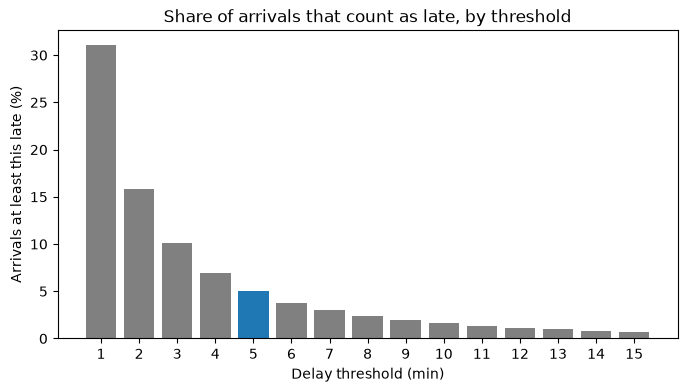

In [8]:
d = dist[dist.delay.between(1, 15)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(d.delay, d.share_at_least * 100, color="grey")
ax.bar(5, d.loc[d.delay == 5, "share_at_least"] * 100, color="tab:blue")
ax.set_xlabel("Delay threshold (min)")
ax.set_ylabel("Arrivals at least this late (%)")
ax.set_title("Share of arrivals that count as late, by threshold")
ax.set_xticks(range(1, 16))
plt.show()

Same numbers as a chart. Most delays are small, after about 5 min it flattens into a long tail.

In [9]:
monthly = con.sql(f"""
    select date_trunc('month', arr_time)::date as month,
           count(*) as arrivals,
           avg((arr_delay >= {DELAY_THRESHOLD_MIN})::int) filter (where not arr_cancelled) as late_rate,
           avg(arr_cancelled::int) as cancel_rate
    from stops
    where arr_time is not null
    group by 1 order by 1
""").df()
monthly

,month,arrivals,late_rate,cancel_rate
0,2024-08-01,1054835,0.044687,0.044094
1,2024-09-01,1021885,0.061880,0.049511
2,2024-10-01,1054383,0.058356,0.038166
3,2024-11-01,1025779,0.084560,0.070038
4,2024-12-01,1046013,0.050340,0.042068
5,2025-01-01,1086797,0.047467,0.066605
6,2025-02-01,980677,0.047439,0.053206
7,2025-03-01,1043557,0.045162,0.053422
8,2025-04-01,1041548,0.043766,0.044619
9,2025-05-01,1069165,0.040036,0.045200


### Late rate over time
Clear season: autumn is bad (8.5% in Nov 2024, 7.5% in Nov 2025), spring and summer sit around 4%. Probably leaves on the track and storms.
Two months with lots of cancellations: June 2025 (NS strikes, 16.6%) and January 2026 (snow, 15.6%).
The strike month isn't more late, trains just didn't run.

This matters for the split. Train has two autumns (~5.3% late), test is only spring/summer (~4.3%).
So a lower score on test is partly just the season. A historical rate fixed on the training months will overestimate on test,
which is why I also use a rolling 28-day rate. I don't use month as a feature, two years is too little to learn that from.

The 2026-09 row is night trains from 31 Aug arriving after midnight, they fall outside the test period.

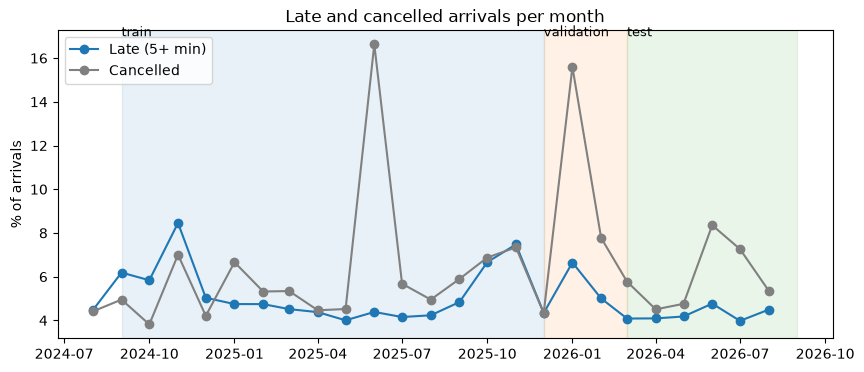

In [10]:
from src.config import TRAIN_START, VAL_START, TEST_START, TEST_END

m = monthly[monthly.arrivals > 10000]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(m.month, m.late_rate * 100, marker="o", label="Late (5+ min)")
ax.plot(m.month, m.cancel_rate * 100, marker="o", color="grey", label="Cancelled")

periods = [(TRAIN_START, VAL_START, "train"), (VAL_START, TEST_START, "validation"), (TEST_START, TEST_END, "test")]
for (start, end, name), color in zip(periods, ["tab:blue", "tab:orange", "tab:green"]):
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=color, alpha=0.1)
    ax.text(pd.Timestamp(start), 17, name, fontsize=9)

ax.set_ylabel("% of arrivals")
ax.set_title("Late and cancelled arrivals per month")
ax.legend(loc="upper left")
plt.show()

Late and cancelled go up together in autumn (weather), but not during the June strikes, then only cancellations jump.
Test period is the calmest part of the whole range.

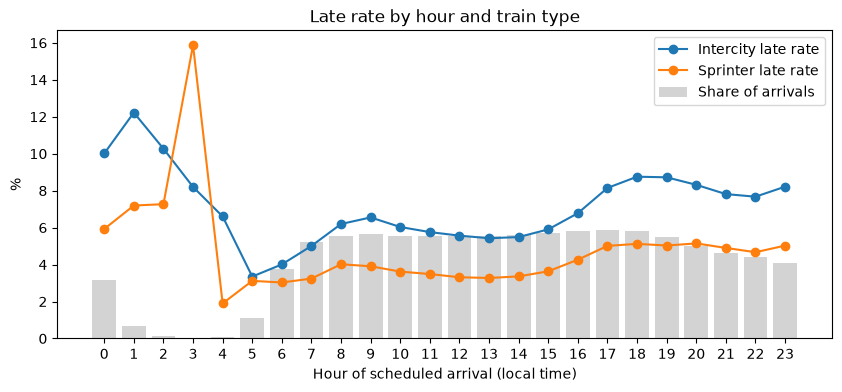

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
train_type,,,,,,,,,,,,,,,,,,,,,,,,
Intercity,10.0,12.2,10.3,8.2,6.6,3.4,4.0,5.0,6.2,6.6,6.0,5.8,5.6,5.4,5.5,5.9,6.8,8.1,8.8,8.7,8.3,7.8,7.7,8.2
Sprinter,5.9,7.2,7.3,15.9,1.9,3.1,3.0,3.2,4.0,3.9,3.6,3.5,3.3,3.3,3.4,3.6,4.3,5.0,5.1,5.0,5.1,4.9,4.7,5.0


In [11]:
by_hour = con.sql(f"""
    select hour(arr_time) as hour, train_type,
           count(*) as arrivals,
           avg((arr_delay >= {DELAY_THRESHOLD_MIN})::int) as late_rate
    from stops
    where arr_time is not null and not arr_cancelled
    group by all
""").df()

rates = by_hour.pivot(index="hour", columns="train_type", values="late_rate") * 100
counts = by_hour.groupby("hour").arrivals.sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(counts.index, counts / counts.sum() * 100, color="lightgrey", label="Share of arrivals")
ax.plot(rates.index, rates["Intercity"], marker="o", label="Intercity late rate")
ax.plot(rates.index, rates["Sprinter"], marker="o", label="Sprinter late rate")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of scheduled arrival (local time)")
ax.set_ylabel("%")
ax.set_title("Late rate by hour and train type")
ax.legend()
plt.show()

rates.round(1).T

### By hour and train type
Delays build up during the day. Early morning is the calmest (~3-5%), there's a small bump at 8-9, and the evening peak 17-19 is the worst (IC ~9%).
That's why I want features about how the network is doing in the last hour, delays clearly spread.
Intercity is late about 1.5x as often as Sprinter at almost every hour, longer trips through busy stations.
The night hours look extreme (Sprinter 16% at 3am) but there are hardly any trains then, so I don't read much into them.

In [12]:
by_day = con.sql(f"""
    select isodow(arr_time) as weekday, train_type,
           count(*) as arrivals,
           avg((arr_delay >= {DELAY_THRESHOLD_MIN})::int) as late_rate
    from stops
    where arr_time is not null and not arr_cancelled
    group by all
""").df()

day_rates = by_day.pivot(index="weekday", columns="train_type", values="late_rate") * 100
day_rates.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
day_rates["arrivals (M)"] = by_day.groupby("weekday").arrivals.sum().values / 1e6
day_rates.round(2)

train_type,Intercity,Sprinter,arrivals (M)
Mon,7.30,4.37,3.77
Tue,7.43,4.40,3.73
Wed,6.70,4.10,3.74
Thu,7.71,4.61,3.78
Fri,6.96,4.14,3.60
Sat,6.20,3.77,3.14
Sun,5.70,3.48,2.93


### By weekday
Weekends are calmer (Sunday IC 5.7% vs ~7-7.7% on weekdays) and have about 20% fewer trains.
Differences between weekdays are small, and each weekday only shows up ~100 times, so a strike day or snow day can shift one.
Weekday matters less than hour of day, but I keep it as a feature, mostly for the weekend effect.

In [13]:
by_station = con.sql(f"""
    select station,
           count(*) as arrivals,
           avg((arr_delay >= {DELAY_THRESHOLD_MIN})::int) as late_rate,
           avg((train_type = 'Intercity')::int) as ic_share
    from stops
    where arr_time is not null and not arr_cancelled
    group by 1
""").df()

print(len(by_station), "stations")
print(by_station.arrivals.describe().round(0))

big = by_station[by_station.arrivals >= 50_000].sort_values("late_rate")
print(len(big), "stations with at least 50k arrivals")
pd.concat([big.head(8), big.tail(8)]).round(3)

278 stations
count       278.0
mean      88829.0
std       86517.0
min           1.0
25%       47981.0
50%       66301.0
75%      102960.0
max      677500.0
Name: arrivals, dtype: float64
203 stations with at least 50k arrivals


,station,arrivals,late_rate,ic_share
13,VNDC,52310,0.020,0.002
59,VTN,84653,0.021,0.000
6,VB,66844,0.022,0.001
246,VNDW,52383,0.023,0.002
60,UTLR,100219,0.024,0.000
182,UTT,84685,0.025,0.000
111,BDG,71690,0.025,0.000
83,APN,71794,0.026,0.000
245,OW,53156,0.082,0.001
79,ZZS,74997,0.084,0.016


### By station
278 stations, very different sizes (median ~66k arrivals, Eindhoven 252k, and some with almost none, checked below).
Among stations with 50k+ arrivals the late rate goes from ~2% to ~10%.
The best ones are all Sprinter-only stops. The worst are mostly Intercity-only stations on two lines: Eindhoven-Venlo (EHV, Deurne, Horst-Sevenum, Blerick) and Zwolle-Deventer (Wijhe, Olst).
So part of the station effect is train type and being far into a long trip, which I also give the model as features.
Not all of it though, some Sprinter stations are at ~8% too, so station stays in as its own feature.

In [14]:
stations_file = RAW / "stations-2023-09.csv"

con.sql(f"""
    select coalesce(s.country, 'NOT IN LIST') as country,
           count(*) as stations, sum(b.arrivals) as arrivals
    from by_station b
    left join read_csv('{stations_file}') s on b.station = s.code
    group by 1 order by arrivals desc
""").show()

con.sql(f"""
    select b.station, b.arrivals, b.late_rate, s.name_long, s.country
    from by_station b
    left join read_csv('{stations_file}') s on b.station = s.code
    where s.code is null or s.country <> 'NL' or b.arrivals < 20000
    order by b.arrivals
""").show(max_rows=40)

┌─────────┬──────────┬──────────┐
│ country │ stations │ arrivals │
│ varchar │  int64   │  int128  │
├─────────┼──────────┼──────────┤
│ NL      │      273 │ 24694331 │
│ B       │        3 │      196 │
│ D       │        2 │        2 │
└─────────┴──────────┴──────────┘

┌─────────┬──────────┬──────────────────────┬─────────────────────────┬─────────┐
│ station │ arrivals │      late_rate       │        name_long        │ country │
│ varchar │  int64   │        double        │         varchar         │ varchar │
├─────────┼──────────┼──────────────────────┼─────────────────────────┼─────────┤
│ WADT    │        1 │                  0.0 │ Waddinxveen Triangel    │ NL      │
│ BH      │        1 │                  1.0 │ Bad Bentheim            │ D       │
│ WAD     │        1 │                  1.0 │ Waddinxveen             │ NL      │
│ ODZ     │        1 │                  1.0 │ Oldenzaal               │ NL      │
│ CO      │        1 │                  0.0 │ Coevorden               │

### Station list check
All station codes are in the 2023 station list, so nothing gets lost when adding coordinates later.
5 foreign stations (Liège, Visé, Bressoux, Bad Bentheim, Kaldenkirchen) with 198 arrivals in total. I only keep NL stations.
About 25 Dutch stations have 1-13 NS arrivals. They're normally served by other operators, NS only shows up there on diversions. Their rates are meaningless but they're so small it doesn't matter.
Rotterdam Stadion stands out: match trains, 12.7% late.

In [15]:
persist = con.sql(f"""
    with seq as (
        select *,
               lag(dep_delay) over (partition by service_id
                                    order by coalesce(arr_time, dep_time), stop_id) as prev_dep_delay
        from stops
    )
    select least(prev_dep_delay, 10) as prev_delay,
           count(*) as arrivals,
           avg((arr_delay >= {DELAY_THRESHOLD_MIN})::int) as late_rate
    from seq
    where arr_time is not null and not arr_cancelled and prev_dep_delay is not null
    group by 1 order by 1
""").df()
persist.round(3)

,prev_delay,arrivals,late_rate
0,0,17154866,0.005
1,1,3837229,0.008
2,2,1375408,0.019
3,3,741203,0.046
4,4,443823,0.167
5,5,282755,0.564
6,6,187320,0.896
7,7,134111,0.973
8,8,100736,0.989
9,9,78705,0.995


### Delays persist
If a train leaves a stop 6+ min late, it arrives at the next stop 5+ min late ~90-99% of the time. With 0-2 min it's under 2%.
So from the previous stop this would be easy, but that stop is usually only minutes before the arrival, way after T0, so I can't use it (leakage).
The real question is how much of this is left one hour before arrival.

In [16]:
from src.config import HORIZON_MIN

t0_state = con.sql(f"""
    with events as (
        select service_id, arr_time + to_minutes(arr_delay) as event_time, arr_delay as delay
        from stops where arr_time is not null and not arr_cancelled
        union all
        select service_id, dep_time + to_minutes(dep_delay), dep_delay
        from stops where dep_time is not null and not dep_cancelled
    ),
    targets as (
        select service_id, arr_delay, arr_time - to_minutes({HORIZON_MIN}) as t0
        from stops where arr_time is not null and not arr_cancelled
    )
    select least(coalesce(e.delay, -1), 10) as delay_at_t0,
           count(*) as arrivals,
           avg((t.arr_delay >= {DELAY_THRESHOLD_MIN})::int) as late_rate
    from targets t
    asof left join events e on t.service_id = e.service_id and t.t0 >= e.event_time
    group by 1 order by 1
""").df()

t0_state["share_of_arrivals"] = t0_state.arrivals / t0_state.arrivals.sum()
t0_state.round(3)

,delay_at_t0,arrivals,late_rate,share_of_arrivals
0,-1,17542724,0.043,0.710
1,0,5199408,0.048,0.211
2,1,1046249,0.063,0.042
3,2,364870,0.084,0.015
4,3,190058,0.107,0.008
5,4,109369,0.144,0.004
6,5,66215,0.198,0.003
7,6,44634,0.262,0.002
8,7,32435,0.335,0.001
9,8,23950,0.428,0.001


### What we know one hour before
71% of arrivals belong to trains that haven't started yet at T0, so there's no information about the train itself.
Those still make up about 61% of all late arrivals, so that's where the hard part is.
For trains that are already running the current delay still helps, but much less than stop to stop:
5 min late at T0 gives ~20% chance of arriving late (vs 56% from the previous stop), 10+ min gives ~75%.
So I need other clues too: network and station in the last hour, history, time, place, weather.